# Pricing Certainty: Short vs Long Debt in US Treasury Issuance
### A Monte Carlo cost-risk study of US Treasury funding

## Introduction

A government, like any large borrower, has to keep refinancing its debt. It can borrow short by rolling over 3-month bills, or borrow long by issuing 10-year bonds. Short debt is usually cheaper, because long yields include a term premium, but its cost follows interest rates: when rates jump, the interest bill jumps soon after. Long debt locks in today's rate, which makes costs predictable but usually more expensive.

**Question:** Over the next 10 years, how do 3-month bills, 2-year notes, 10-year bonds and mixes of bills and bonds compare on expected interest cost, and on the risk of a very expensive year?

**Data:** Daily US Treasury constant-maturity yields from FRED for the 3-month (`DGS3MO`), 2-year (`DGS2`) and 10-year (`DGS10`) maturities, January 1990 to October 2026, converted to month-end values.

**Method in brief:**
1. Fitting the Vasicek short-rate model to the 3-month yield and checking how reliable the estimates are.
2. Validating the model by comparing Monte Carlo results with exact formulas.
3. Simulating 20,000 ten-year paths of the short rate and building 2-year and 10-year yields from them.
4. Running each borrowing strategy as a rolling debt ladder and recording its average cost and its most expensive year.
5. Testing how the results change with the model's parameters, and comparing them with what actually happened historically.

**Main findings (details at the end):** Bills are the cheapest choice on average under every reasonable assumption, while 10-year bonds protect against an expensive year. A portfolio of about 10% bills and 90% bonds beats holding only bonds on both cost and worst-year risk.

## Part 1: Data

I load the three yield series from a saved file (`fred_yields_pinned.csv`) if it exists, and download them from FRED otherwise. Saving the data means the notebook gives the same results every time it runs, even if FRED revises its data or is unavailable. Daily yields are converted to month-end values, because the simulation moves in monthly steps, and from percent to decimals.

The plot shows the main episodes in the sample: the 2008 financial crisis, the near-zero rates of 2009 to 2015, and the rate hikes of 2022 and 2023. The last 3-month yield in the data (October 2026) is the starting point of every simulated path.

Loading cached data from fred_yields_pinned.csv


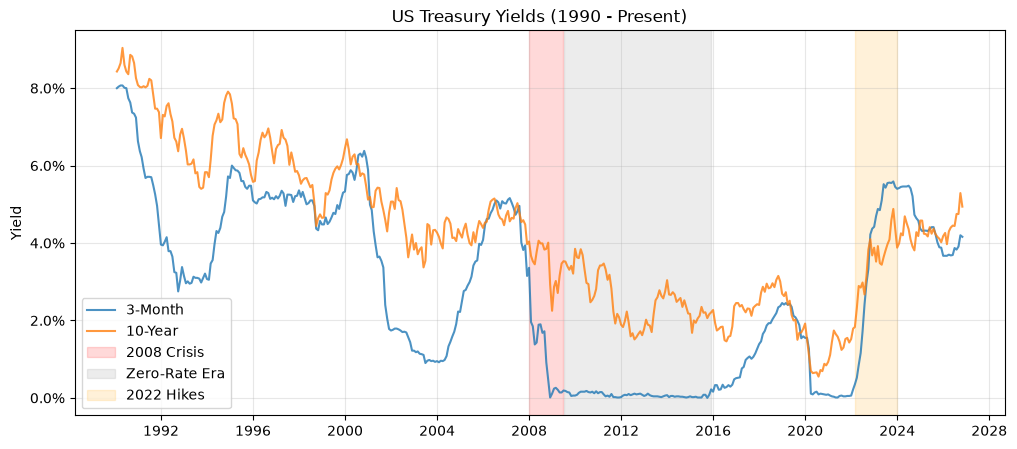

In [1]:
import numpy as np
import pandas as pd
import pandas_datareader as pdr
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import root_scalar
import matplotlib.ticker as mtick
import os

start_date = '1990-01-01'
end_date = '2026-10-31'
tickers = ['DGS3MO', 'DGS2', 'DGS10']
csv_file = 'fred_yields_pinned.csv'

if os.path.exists(csv_file):
    print(f"Loading cached data from {csv_file}")
    df = pd.read_csv(csv_file, index_col=0, parse_dates=True)
else:
    print("Downloading FRED data...")
    df = pdr.get_data_fred(tickers, start=start_date, end=end_date).dropna()
    df.to_csv(csv_file)
    print(f"Data saved to {csv_file}")

df_monthly = df.resample('ME').last() / 100.0 # Resampling to month-end (ME) and converting to decimals

hist_3m = df_monthly['DGS3MO'].values
hist_2y = df_monthly['DGS2'].values
hist_10y = df_monthly['DGS10'].values
current_r = hist_3m[-1]

plt.figure(figsize=(12, 5))
plt.plot(df_monthly.index, df_monthly['DGS3MO'], label='3-Month', alpha=0.8)
plt.plot(df_monthly.index, df_monthly['DGS10'], label='10-Year', alpha=0.8)
plt.axvspan('2008-01-01', '2009-06-30', color='red', alpha=0.15, label='2008 Crisis')
plt.axvspan('2009-07-01', '2015-11-30', color='gray', alpha=0.15, label='Zero-Rate Era')
plt.axvspan('2022-03-01', '2023-12-31', color='orange', alpha=0.15, label='2022 Hikes')

plt.title("US Treasury Yields (1990 - Present)")
plt.ylabel("Yield")
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Part 2: Fitting the Vasicek model and checking it

The Vasicek model describes the short rate $r_t$ as a random process that is pulled back towards a long-run level:

$$dr_t = \kappa(\theta - r_t)\,dt + \sigma\,dW_t$$

Here, $\theta$ is the long-run level, $\kappa$ is the speed of mean reversion and $\sigma$ is the volatility. Observed once a month, the model becomes an AR(1) process:

$$r_{t+\Delta} = \theta + (r_t - \theta)\,e^{-\kappa\Delta} + \varepsilon_t$$

So, I regress next month's 3-month yield on this month's, and convert the intercept, slope and residual variance into $\kappa$, $\theta$ and $\sigma$. The half-life $\ln 2/\kappa$ is the time it takes for a shock to the rate to fade by half.

**How reliable are the estimates?** The estimates are not very reliable, and the regression standard errors show it. The 95% range for the slope gives a half-life anywhere between about 3 and 52 years. The intercept is only 1.2 standard errors from zero, so $\theta$ (estimated at 1.94%, pulled down by the years of near-zero rates) is poorly pinned down. This is why Part 5 tests $\theta$ between 2% and 5%.

**Bond-price check.** Vasicek has an exact formula for the price of a zero-coupon bond, $P(\tau) = A(\tau)\,e^{-B(\tau)\,r}$. I compare it with a Monte Carlo price for a 2-year bond, found by simulating the short rate and averaging $e^{-\int r\,dt}$ over 200,000 paths. I use the trapezoid rule for the integral, because a simple left-endpoint sum gives a small bias with monthly steps. The two prices agree to within simulation error (0.92481 exact, 0.92479 with monthly steps, 0.92481 with weekly steps).

**Term premium proxy.** The model's 10-year yield is usually below the actual 10-year yield, so I plot the gap between them. It is a rough proxy for the term premium, the extra yield investors want for holding long bonds, but it also contains model error. Its historical average, about 1.8 percentage points, is used to build long yields in Part 3.

In [2]:
rng_val = np.random.default_rng(1) # Isolated random generator for validation to prevent cross-contamination

# Vasicek Calibration
dt = 1/12
rt = hist_3m[:-1]
rt_plus_1 = hist_3m[1:]

X = sm.add_constant(rt)
model = sm.OLS(rt_plus_1, X).fit()
a, b = model.params
a_se, b_se = model.bse[0], model.bse[1]
residual_var = model.resid.var()

kappa = -np.log(b) / dt
theta = a / (1 - b)
sigma = np.sqrt(residual_var * 2 * kappa / (1 - np.exp(-2 * kappa * dt)))
half_life = np.log(2) / kappa

print("--- CALIBRATED PARAMETERS ---")
print(f"kappa = {kappa:.4f}, theta = {theta:.4f}, sigma = {sigma:.4f}\n")

b_ci = [b - 2*b_se, b + 2*b_se]
k_high = -np.log(b_ci[0]) / dt
k_low = -np.log(min(b_ci[1], 0.999)) / dt 

print("--- MODEL IDENTIFICATION WARNING ---")
print(f"1. Mean Reversion is Weak: The slope's 95% interval implies kappa ranges from {k_low:.3f} to {k_high:.3f}.")
print(f"   Consequently, the half-life is anywhere from {np.log(2)/k_high:.1f} to {np.log(2)/max(k_low, 0.001):.1f} years.")
print(f"2. Theta is Barely Identified: The intercept (a) is only {a/a_se:.1f} standard errors from zero.")
print(f"   The model assumes rates sink to {theta:.2%}, but statistical evidence for this is weak.\n")

--- CALIBRATED PARAMETERS ---
kappa = 0.1211, theta = 0.0194, sigma = 0.0074

--- MODEL IDENTIFICATION WARNING ---
1. Mean Reversion is Weak: The slope's 95% interval implies kappa ranges from 0.013 to 0.230.
   Consequently, the half-life is anywhere from 3.0 to 52.2 years.
2. Theta is Barely Identified: The intercept (a) is only 1.2 standard errors from zero.
   The model assumes rates sink to 1.94%, but statistical evidence for this is weak.



--- VALIDATION SUITE ---
2Y Zero-Coupon Bond Price:
Closed Form:  0.92481
MC (12/yr):   0.92479 (SE: 0.00002)
MC (52/yr):   0.92481 (SE: 0.00002)



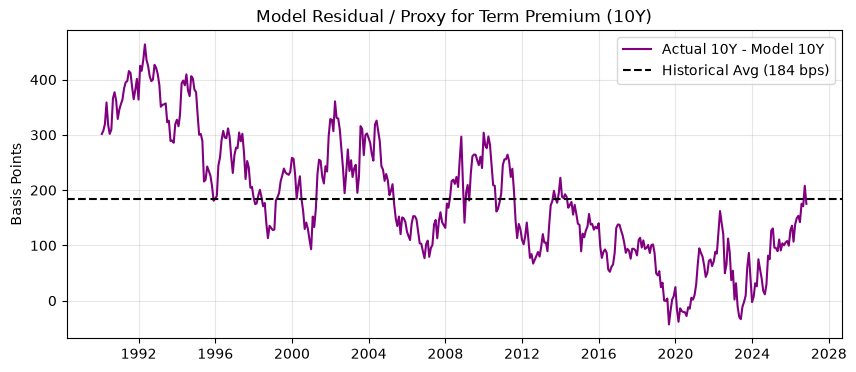

In [3]:
# Vasicek Functions
def get_A_B(k_val, th_val, s_val, tau):
    B = (1 - np.exp(-k_val * tau)) / k_val
    A = np.exp((th_val - s_val**2 / (2 * k_val**2)) * (B - tau) - (s_val**2 / (4 * k_val)) * B**2)
    return A, B

def model_yield(k_val, th_val, s_val, tau, r_array):
    A, B = get_A_B(k_val, th_val, s_val, tau)
    return - (1/tau) * np.log(A * np.exp(-B * r_array))

# Validation Suite (Trapezoid Rule)
print("--- VALIDATION SUITE ---")
tau_val = 2.0
A_v, B_v = get_A_B(kappa, theta, sigma, tau_val)
P_closed = A_v * np.exp(-B_v * current_r)

def mc_bond_price(steps_per_year):
    N_val = 200000
    dt_val = 1 / steps_per_year
    steps = int(tau_val * steps_per_year)
    var_mult = sigma * np.sqrt(dt_val)
    
    r_v = np.full(N_val, current_r)
    int_r = np.zeros(N_val)
    
    for t in range(steps):
        # Draw normals inside the loop to cap memory overhead
        Z_t = rng_val.standard_normal(N_val) 
        r_new = r_v + kappa * (theta - r_v) * dt_val + var_mult * Z_t
        int_r += 0.5 * (r_v + r_new) * dt_val # Trapezoid rule eliminates left-endpoint bias
        r_v = r_new
    return np.mean(np.exp(-int_r)), np.std(np.exp(-int_r)) / np.sqrt(N_val)

p_12, se_12 = mc_bond_price(12)
p_52, se_52 = mc_bond_price(52)

print(f"2Y Zero-Coupon Bond Price:")
print(f"Closed Form:  {P_closed:.5f}")
print(f"MC (12/yr):   {p_12:.5f} (SE: {se_12:.5f})")
print(f"MC (52/yr):   {p_52:.5f} (SE: {se_52:.5f})\n")

# Term Premium (Model Residual) Plot
mod_10y_hist = model_yield(kappa, theta, sigma, 10.0, hist_3m)
spread_10y = hist_10y - mod_10y_hist

plt.figure(figsize=(10, 4))
plt.plot(df_monthly.index, spread_10y * 10000, label='Actual 10Y - Model 10Y', color='purple')
plt.axhline(np.mean(spread_10y)*10000, color='black', linestyle='--', label=f'Historical Avg ({np.mean(spread_10y)*10000:.0f} bps)')
plt.title("Model Residual / Proxy for Term Premium (10Y)")
plt.ylabel("Basis Points")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Part 3: Simulating interest rates and debt ladders

**Short rate.** I simulate 20,000 paths of the 3-month yield over 10 years in monthly steps, starting from today's value. I use the exact Vasicek transition from Part 2, so the monthly steps add no discretisation error.

**Long yields.** For each simulated short rate, I compute the Vasicek 2-year and 10-year yields and add a term premium. The premium starts at today's gap between the actual and model yield, so the simulated curve starts at today's actual yields. It then decays towards its historical average at the same speed $\kappa$. This is an assumption, and it is discussed under the limitations listed in the README.

**Debt ladders.** Each strategy is a rolling ladder rather than a single issue. For a maturity of $M$ months, $1/M$ of the debt matures each month and is reissued at that month's yield. The cost of the portfolio in any month is the average yield of the debt still outstanding, which is a rolling mean of the issue yields over the past $M$ months. The strategies are 100% 3-month bills ($M = 3$), 100% 2-year notes ($M = 24$), 100% 10-year bonds ($M = 120$) and a 50/50 mix of bills and bonds.

**Starting the ladders.** There are two versions:
- *Legacy:* the ladder starts with the debt actually issued over the past $M$ months, like a Treasury that has already been following the strategy.
- *New issuance:* the ladder starts as if all existing debt had been issued at today's yield, so the results depend only on today's conditions and future rates. Most results use this version.

**Measures, calculated for each path:**
- *Average cost:* the mean portfolio cost over the 10 years.
- *Peak-year cost:* the highest of the 10 annual average costs, which is the most expensive single year.

For each measure, I report the mean over all paths and the 95th percentile, which is a bad but not extreme outcome.

**Checks.** About 9% of paths go below zero at some point, which is a known feature of the Vasicek model (see the limitations in the README). The simulated average 3-month rate matches its exact expected value (3.2203% simulated, 3.2204% exact, standard error 0.0063%).

In [4]:
rng_sim = np.random.default_rng(42) # Dedicated random generator for the main simulation

# Global Simulator Constants
N_paths = 20000
years = 10
months = years * 12
dt_sim = 1/12
t_grid = np.arange(1, months + 1) * dt_sim
epsilon_matrix = rng_sim.standard_normal((N_paths, months))

def evaluate_ladder(hist_series, sim_series, M, seed_type, n_paths, sim_months, sim_years):
    if seed_type == 'legacy':
        prefix = hist_series[-M:] if M > 0 else np.array([])
    else: 
        prefix = np.full(M, hist_series[-1]) if M > 0 else np.array([])
        
    full_series = np.concatenate([np.tile(prefix, (n_paths, 1)), sim_series], axis=1)
    
    port_costs = np.array([full_series[:, i : i+M].mean(axis=1) for i in range(1, sim_months + 1)]).T
    annual_averages = port_costs.reshape(n_paths, sim_years, 12).mean(axis=2)
    
    return {
        'mean_array': port_costs.mean(axis=1),
        'peak_array': annual_averages.max(axis=1),
        'annual_averages': annual_averages
    }

def simulate_strategy(k_sim, th_sim, s_sim, eps_mat, hist3, hist2, hist10, cur_r, t_arr, seed_type):
    mod_2y_h = model_yield(k_sim, th_sim, s_sim, 2.0, hist3)
    mod_10y_h = model_yield(k_sim, th_sim, s_sim, 10.0, hist3)
    tp_2y_h_avg = np.mean(hist2 - mod_2y_h)
    tp_10y_h_avg = np.mean(hist10 - mod_10y_h)
    
    gap_2y = hist2[-1] - model_yield(k_sim, th_sim, s_sim, 2.0, cur_r)
    gap_10y = hist10[-1] - model_yield(k_sim, th_sim, s_sim, 10.0, cur_r)
    
    tp_2y_t = tp_2y_h_avg + (gap_2y - tp_2y_h_avg) * np.exp(-k_sim * t_arr)
    tp_10y_t = tp_10y_h_avg + (gap_10y - tp_10y_h_avg) * np.exp(-k_sim * t_arr)
    
    # Simulating Short Rate
    paths_r = np.zeros((eps_mat.shape[0], eps_mat.shape[1] + 1))
    paths_r[:, 0] = cur_r
    decay = np.exp(-k_sim * dt_sim)
    v_mult = s_sim * np.sqrt((1 - np.exp(-2 * k_sim * dt_sim)) / (2 * k_sim))
    
    for t in range(eps_mat.shape[1]):
        paths_r[:, t+1] = th_sim + (paths_r[:, t] - th_sim) * decay + v_mult * eps_mat[:, t]
    sim_3M = paths_r[:, 1:]
    
    # Long Yields
    sim_2Y = model_yield(k_sim, th_sim, s_sim, 2.0, sim_3M) + tp_2y_t
    sim_10Y = model_yield(k_sim, th_sim, s_sim, 10.0, sim_3M) + tp_10y_t

    # Ladders
    c_3m = evaluate_ladder(hist3, sim_3M, 3, seed_type, eps_mat.shape[0], eps_mat.shape[1], years)
    c_2y = evaluate_ladder(hist2, sim_2Y, 24, seed_type, eps_mat.shape[0], eps_mat.shape[1], years)
    c_10y = evaluate_ladder(hist10, sim_10Y, 120, seed_type, eps_mat.shape[0], eps_mat.shape[1], years)
    
    mix_mean = 0.5 * c_3m['mean_array'] + 0.5 * c_10y['mean_array']
    mix_annual = 0.5 * c_3m['annual_averages'] + 0.5 * c_10y['annual_averages']
    mix_peak = mix_annual.max(axis=1)

    return {
        'paths_r': paths_r,
        '100% 3M Bills': c_3m,
        '100% 2Y Notes': c_2y,
        '100% 10Y Bonds': c_10y,
        '50/50 3M/10Y': {
            'mean_array': mix_mean,
            'peak_array': mix_peak,
            'annual_averages': mix_annual
        }
    }

res_legacy = simulate_strategy(kappa, theta, sigma, epsilon_matrix, hist_3m, hist_2y, hist_10y, current_r, t_grid, 'legacy')
res_new = simulate_strategy(kappa, theta, sigma, epsilon_matrix, hist_3m, hist_2y, hist_10y, current_r, t_grid, 'new')

# Validation Checks
discrete_analytic_E = np.mean(theta + (current_r - theta) * np.exp(-kappa * t_grid))
sim_E = np.mean(res_new['paths_r'][:, 1:])
sim_E_se = np.std(np.mean(res_new['paths_r'][:, 1:], axis=1)) / np.sqrt(N_paths)

print("--- SIMULATION VALIDATION ---")
print(f"Negative Rate Paths: {np.mean(res_new['paths_r'].min(axis=1) < 0):.2%} of paths dip below zero")
print(f"Discrete Expected 3M Avg: Analytic = {discrete_analytic_E:.4%} | Simulated = {sim_E:.4%} (SE: {sim_E_se:.4%})")

--- SIMULATION VALIDATION ---
Negative Rate Paths: 9.02% of paths dip below zero
Discrete Expected 3M Avg: Analytic = 3.2204% | Simulated = 3.2203% (SE: 0.0063%)


## Part 4: The cost-risk frontier

I combine bills and 10-year bonds in steps of 5% and plot, for each mix, the expected average cost against the 95th percentile of the peak-year cost.

On the 10-year average cost, bills beat bonds on both the mean and the 95th percentile, so there is no real trade-off on that measure. The trade-off appears in the worst single year: bills are cheaper on average, but they can have a very expensive year when rates rise, while bonds are steadier.

The curve bends to the left at the 100% bond end. A portfolio of about 10% bills and 90% bonds has both a lower expected cost (about 4.6% against 4.75%) and a lower peak-year cost (about 5.27% against 5.30%) than 100% bonds, so holding only bonds is never the best choice in this model. The reason is timing. The worst years for the bill ladder and for the bond ladder don't always coincide, so a small share of bills smooths out the worst year. In a one-factor model, every yield is driven by the same random shock, so this timing effect is the only kind of diversification the model can show.

From the 10% mix down to 100% bills, each extra share of bills lowers the expected cost but raises the peak-year risk. That part of the curve is the efficient frontier.

--- EXACT VALUES FOR MINIMUM RISK MIX ---
Minimum-Risk Mix (3M Bills / 10Y Bonds): 10% / 90%
Expected 10-Year Avg Cost:          4.5997%
Peak-Year Risk (95th Percentile):   5.2722%



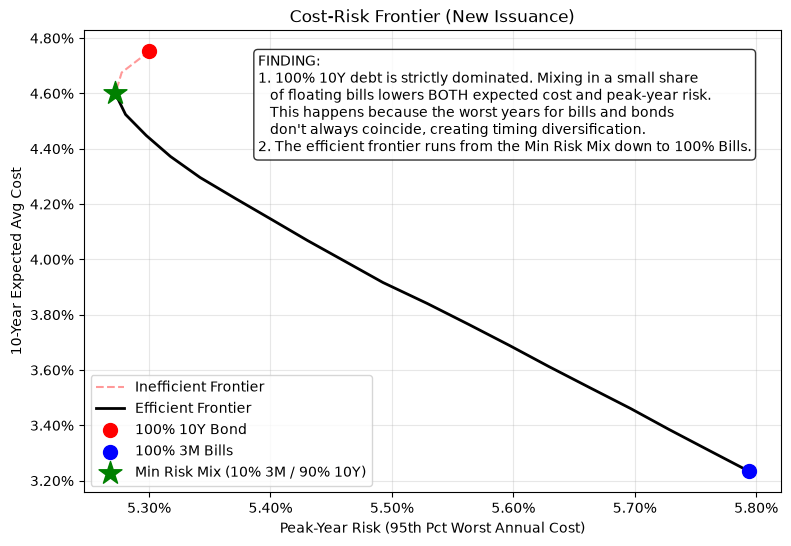

In [5]:
mixes = np.linspace(0, 1, 21)
exp_costs = []
risk_costs = []

for w in mixes:
    mix_mean = w * res_new['100% 3M Bills']['mean_array'] + (1 - w) * res_new['100% 10Y Bonds']['mean_array']
    mix_annual = w * res_new['100% 3M Bills']['annual_averages'] + (1 - w) * res_new['100% 10Y Bonds']['annual_averages']
    mix_peak = mix_annual.max(axis=1)
    
    exp_costs.append(np.mean(mix_mean) * 100)
    risk_costs.append(np.percentile(mix_peak, 95) * 100)

min_risk_idx = np.argmin(risk_costs)
min_risk_w = mixes[min_risk_idx]

print("--- EXACT VALUES FOR MINIMUM RISK MIX ---")
print(f"Minimum-Risk Mix (3M Bills / 10Y Bonds): {min_risk_w*100:.0f}% / {(1-min_risk_w)*100:.0f}%")
print(f"Expected 10-Year Avg Cost:          {exp_costs[min_risk_idx]:.4f}%")
print(f"Peak-Year Risk (95th Percentile):   {risk_costs[min_risk_idx]:.4f}%\n")

plt.figure(figsize=(9, 6))

plt.plot(risk_costs[:min_risk_idx+1], exp_costs[:min_risk_idx+1], 'r--', alpha=0.4, label='Inefficient Frontier')
plt.plot(risk_costs[min_risk_idx:], exp_costs[min_risk_idx:], 'k-', linewidth=2, label='Efficient Frontier')

plt.scatter(risk_costs[0], exp_costs[0], color='red', s=100, label='100% 10Y Bond', zorder=5)
plt.scatter(risk_costs[-1], exp_costs[-1], color='blue', s=100, label='100% 3M Bills', zorder=5)
plt.scatter(risk_costs[min_risk_idx], exp_costs[min_risk_idx], color='green', marker='*', s=300, 
            label=f'Min Risk Mix ({min_risk_w*100:.0f}% 3M / {(1-min_risk_w)*100:.0f}% 10Y)', zorder=6)

plt.title("Cost-Risk Frontier (New Issuance)")
plt.xlabel("Peak-Year Risk (95th Pct Worst Annual Cost)")
plt.ylabel("10-Year Expected Avg Cost")
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter())
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter())

plt.text(0.25, 0.95, "FINDING:\n1. 100% 10Y debt is strictly dominated. Mixing in a small share\n   of floating bills lowers BOTH expected cost and peak-year risk.\n   This happens because the worst years for bills and bonds\n   don't always coincide, creating timing diversification.\n2. The efficient frontier runs from the Min Risk Mix down to 100% Bills.", 
         transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.show()

## Part 5: Sensitivity and break-even analysis

Because $\theta$ and $\kappa$ are poorly estimated, I check how much the results change when the parameters change. Every scenario reuses the same random numbers, so differences between scenarios come from the parameters and not from simulation noise.

**Seed check.** Rerunning the base case with a different set of random numbers (seed 43) changes the expected bill cost by 0.2 basis points and the 10-year peak-year risk by 1.6 basis points, and the minimum-risk mix stays at 10% bills. Thus, the results are not an accident of one random draw.

**Sensitivity table.** The table shows the legacy and new-issuance base cases, then new issuance with $\theta$ = 2%, 3%, 4% and 5%, and with $\sigma$ 50% higher. The columns are:
- *Exp Avg Cost:* the mean of the 10-year average cost.
- *Risk (95th Avg):* the 95th percentile of the 10-year average cost.
- *Peak Yr (95th):* the 95th percentile of the peak-year cost.

Whenever $\theta$ or $\sigma$ changes, I re-estimate the term premium, so that the model still matches the average historical yields.

**Break-even $\theta$.** I search numerically for the value of $\theta$ at which bills and 10-year bonds have the same expected cost. The answer is 6.59%. This is above the range tested in the table and far above the estimated 1.94%, so in this model long debt is almost never cheaper on average. Its value is in limiting bad years.

In [6]:
def generate_table(r_dict, name):
    rows = []
    for strat in ['100% 3M Bills', '100% 2Y Notes', '100% 10Y Bonds', '50/50 3M/10Y']:
        rows.append({
            'Scenario': name,
            'Strategy': strat,
            'Exp Avg Cost': np.mean(r_dict[strat]['mean_array']),
            'Risk (95th Avg)': np.percentile(r_dict[strat]['mean_array'], 95),
            'Peak Yr (95th)': np.percentile(r_dict[strat]['peak_array'], 95)
        })
    return pd.DataFrame(rows)

# Seed Stability Check
rng_alt = np.random.default_rng(43)
eps_alt = rng_alt.standard_normal((N_paths, months))
res_alt = simulate_strategy(kappa, theta, sigma, eps_alt, hist_3m, hist_2y, hist_10y, current_r, t_grid, 'new')

base_3m_cost = np.mean(res_new['100% 3M Bills']['mean_array'])
alt_3m_cost = np.mean(res_alt['100% 3M Bills']['mean_array'])
diff_3m_bps = abs(base_3m_cost - alt_3m_cost) * 10000

base_10y_risk = np.percentile(res_new['100% 10Y Bonds']['peak_array'], 95)
alt_10y_risk = np.percentile(res_alt['100% 10Y Bonds']['peak_array'], 95)
diff_10y_bps = abs(base_10y_risk - alt_10y_risk) * 10000

mixes_alt = np.linspace(0, 1, 21)
risk_costs_alt = []
for w in mixes_alt:
    mix_annual_alt = w * res_alt['100% 3M Bills']['annual_averages'] + (1 - w) * res_alt['100% 10Y Bonds']['annual_averages']
    risk_costs_alt.append(np.percentile(mix_annual_alt.max(axis=1), 95) * 100)

min_risk_idx_alt = np.argmin(risk_costs_alt)
min_risk_w_alt = mixes_alt[min_risk_idx_alt]

print("--- MONTE CARLO STABILITY (Seed 42 vs Seed 43) ---")
print(f"3M Exp Cost:       Seed 42 = {base_3m_cost:.4%} | Seed 43 = {alt_3m_cost:.4%} | Diff = {diff_3m_bps:.1f} bps")
print(f"10Y Peak Risk:     Seed 42 = {base_10y_risk:.4%} | Seed 43 = {alt_10y_risk:.4%} | Diff = {diff_10y_bps:.1f} bps")
print(f"Min-Risk Mix (3M): Seed 42 = {min_risk_w*100:.0f}%      | Seed 43 = {min_risk_w_alt*100:.0f}%")
print("Conclusion: Results are stable to within a few basis points across seeds, and the")
print("structural presence of the efficient frontier bend remains robust.\n")

--- MONTE CARLO STABILITY (Seed 42 vs Seed 43) ---
3M Exp Cost:       Seed 42 = 3.2332% | Seed 43 = 3.2352% | Diff = 0.2 bps
10Y Peak Risk:     Seed 42 = 5.3000% | Seed 43 = 5.3160% | Diff = 1.6 bps
Min-Risk Mix (3M): Seed 42 = 10%      | Seed 43 = 10%
Conclusion: Results are stable to within a few basis points across seeds, and the
structural presence of the efficient frontier bend remains robust.



In [7]:
dfs = []
# Base Cases
dfs.append(generate_table(res_legacy, f'Base (Legacy) Theta={theta*100:.2f}%'))
dfs.append(generate_table(res_new, f'Base (New Issuance) Theta={theta*100:.2f}%'))

# Sensitivities (New Issuance)
for th_val in [0.02, 0.03, 0.04, 0.05]:
    r = simulate_strategy(kappa, th_val, sigma, epsilon_matrix, hist_3m, hist_2y, hist_10y, current_r, t_grid, 'new')
    dfs.append(generate_table(r, f'Sens (New): Theta={th_val*100:.0f}%'))

r_sig = simulate_strategy(kappa, theta, sigma * 1.5, epsilon_matrix, hist_3m, hist_2y, hist_10y, current_r, t_grid, 'new')
dfs.append(generate_table(r_sig, f'Sens (New): Sigma +50%'))

df_sens = pd.concat(dfs, ignore_index=True)
format_dict = {'Exp Avg Cost': '{:.2%}', 'Risk (95th Avg)': '{:.2%}', 'Peak Yr (95th)': '{:.2%}'}

print("--- FULL SENSITIVITY TABLE ---")
display(df_sens.style.format(format_dict).set_properties(**{'text-align': 'right'}))

# Break-even Analysis
def cost_diff_for_theta(th_test):
    r = simulate_strategy(kappa, th_test, sigma, epsilon_matrix, hist_3m, hist_2y, hist_10y, current_r, t_grid, 'new')
    return np.mean(r['100% 3M Bills']['mean_array']) - np.mean(r['100% 10Y Bonds']['mean_array'])

breakeven_theta = root_scalar(cost_diff_for_theta, bracket=[0.01, 0.08]).root
print(f"\nBREAK-EVEN ANALYSIS:")
print(f"Long debt (10Y) only yields a lower expected cost than floating bills if the long-term equilibrium rate (Theta) is above {breakeven_theta:.2%}.")

--- FULL SENSITIVITY TABLE ---


,Scenario,Strategy,Exp Avg Cost,Risk (95th Avg),Peak Yr (95th)
0,Base (Legacy) Theta=1.94%,100% 3M Bills,3.23%,4.69%,5.79%
1,Base (Legacy) Theta=1.94%,100% 2Y Notes,3.76%,4.93%,5.76%
2,Base (Legacy) Theta=1.94%,100% 10Y Bonds,4.00%,4.38%,5.27%
3,Base (Legacy) Theta=1.94%,50/50 3M/10Y,3.62%,4.53%,5.28%
4,Base (New Issuance) Theta=1.94%,100% 3M Bills,3.23%,4.69%,5.79%
5,Base (New Issuance) Theta=1.94%,100% 2Y Notes,3.81%,4.98%,5.76%
6,Base (New Issuance) Theta=1.94%,100% 10Y Bonds,4.75%,5.13%,5.30%
7,Base (New Issuance) Theta=1.94%,50/50 3M/10Y,3.99%,4.90%,5.46%
8,Sens (New): Theta=2%,100% 3M Bills,3.26%,4.71%,5.82%
9,Sens (New): Theta=2%,100% 2Y Notes,3.83%,5.00%,5.79%



BREAK-EVEN ANALYSIS:
Long debt (10Y) only yields a lower expected cost than floating bills if the long-term equilibrium rate (Theta) is above 6.59%.


## Part 6: Historical backtest

Here, I apply the same ladder calculation to actual yields instead of simulated ones. For every 10-year window starting between 1999 and 2016, I compare the average cost of the 3-month ladder with the 10-year and 2-year ladders. Each ladder starts with the debt actually issued in the years before the window (the legacy setup).

Bills were cheaper than the 10-year ladder in 98% of windows, and cheaper than the 2-year ladder in 81%. In the worst window, bills cost only 12 basis points more than the bond ladder. A ladder reprices only part of its debt each year, so even the 2022 hikes reached only a fraction of the bond portfolio.

There are two cautions that apply. The windows overlap heavily, so together they cover only two or three independent periods. They also fall mostly inside the long decline in interest rates since the 1980s, which favours short-term borrowing. The backtest agrees with the simulation, but it cannot show how bills would do in a long period of rising rates.

--- OVERLAPPING HISTORICAL LADDER BACKTEST ---
* Windows range from 1999 to 2016. Overlapping 10-year structures across 
  this time span effectively represents only a few independent intervals, 
  all mostly contained within a massive secular bond bull market.

Windows where 3M Ladder beat 10Y Ladder: 98.0%
Windows where 3M Ladder beat 2Y Ladder:  81.4%

Worst case for Bills vs 10Y Ladder: +12 bps
  (Note: The ladder structure spreads issuance over 10 years, meaning the 2022
  rate hikes only re-priced a fraction of the portfolio, muting the worst-case scenario).


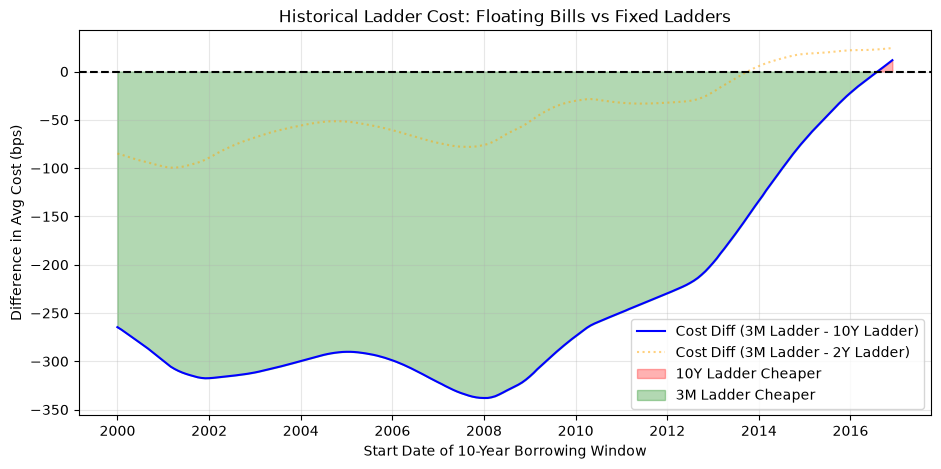

In [8]:
def eval_hist_ladder(hist_series_arr, window_series_arr, M):
    full = np.concatenate([hist_series_arr[-(M-1):] if M > 1 else [], window_series_arr])
    return pd.Series(full).rolling(M).mean().dropna().mean()

start_indices = range(119, len(df_monthly) - 120 + 1)
diffs_10y, diffs_2y, start_dates = [], [], []

for i in start_indices:
    history = df_monthly.iloc[i-119 : i+1] 
    window = df_monthly.iloc[i : i+120]
    
    c_3m = eval_hist_ladder(history['DGS3MO'].values[:-1], window['DGS3MO'].values, 3)
    c_2y = eval_hist_ladder(history['DGS2'].values[:-1], window['DGS2'].values, 24)
    c_10y = eval_hist_ladder(history['DGS10'].values[:-1], window['DGS10'].values, 120)
    
    diffs_10y.append(c_3m - c_10y)
    diffs_2y.append(c_3m - c_2y)
    start_dates.append(window.index[0])

diffs_10y = np.array(diffs_10y)
diffs_2y = np.array(diffs_2y)

dt_start, dt_end = start_dates[0].strftime('%Y'), start_dates[-1].strftime('%Y')

print("--- OVERLAPPING HISTORICAL LADDER BACKTEST ---")
print(f"* Windows range from {dt_start} to {dt_end}. Overlapping 10-year structures across ")
print("  this time span effectively represents only a few independent intervals, ")
print("  all mostly contained within a massive secular bond bull market.")
print(f"\nWindows where 3M Ladder beat 10Y Ladder: {np.mean(diffs_10y < 0):.1%}")
print(f"Windows where 3M Ladder beat 2Y Ladder:  {np.mean(diffs_2y < 0):.1%}")
print(f"\nWorst case for Bills vs 10Y Ladder: +{np.max(diffs_10y)*10000:.0f} bps")
print("  (Note: The ladder structure spreads issuance over 10 years, meaning the 2022")
print("  rate hikes only re-priced a fraction of the portfolio, muting the worst-case scenario).")

plt.figure(figsize=(11, 5))
plt.plot(start_dates, diffs_10y * 10000, color='blue', label='Cost Diff (3M Ladder - 10Y Ladder)')
plt.plot(start_dates, diffs_2y * 10000, color='orange', alpha=0.5, linestyle=':', label='Cost Diff (3M Ladder - 2Y Ladder)')

plt.axhline(0, color='black', linestyle='--')
plt.fill_between(start_dates, 0, diffs_10y * 10000, where=(diffs_10y > 0), 
                 color='red', alpha=0.3, label='10Y Ladder Cheaper', interpolate=True)
plt.fill_between(start_dates, 0, diffs_10y * 10000, where=(diffs_10y < 0), 
                 color='green', alpha=0.3, label='3M Ladder Cheaper', interpolate=True)

plt.title("Historical Ladder Cost: Floating Bills vs Fixed Ladders")
plt.ylabel("Difference in Avg Cost (bps)")
plt.xlabel("Start Date of 10-Year Borrowing Window")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Results and conclusions

Base case, new issuance:

| Strategy | Expected average cost | 95th percentile of average cost | 95th percentile of peak-year cost |
| --- | --- | --- | --- |
| 100% 3-month bills | 3.23% | 4.69% | 5.79% |
| 100% 2-year notes | 3.81% | 4.98% | 5.76% |
| 100% 10-year bonds | 4.75% | 5.13% | 5.30% |
| 50/50 bills and bonds | 3.99% | 4.90% | 5.46% |

1. **Bills are the cheapest choice on average.** They cost about 1.5 percentage points a year less than 10-year bonds (3.23% against 4.75%). On \$1 trillion of debt, that is roughly \$15 billion a year.
2. **Long debt protects against a bad year.** The 95th percentile of the worst annual cost is 5.30% for bonds against 5.79% for bills. With 50% higher volatility the gap widens: 7.14% for bills against 5.70% for bonds.
3. **Holding only long debt is never optimal.** About 10% bills and 90% bonds lowers both the expected cost and the peak-year risk compared with 100% bonds. This result is the same with a different random seed.
4. **Long debt only wins on average cost if the long-run rate is above about 6.6%,** far above what the data suggests.
5. **History agrees.** Bills were cheaper in 98% of past 10-year windows, although that sample is dominated by falling rates.

The legacy case gives a lower cost for 10-year bonds (4.00%) than the new-issuance case, because a running ladder still holds bonds issued when rates were low. This shows how much the starting position matters for a real borrower.

**In short:** Choosing between short and long debt is choosing how much to pay for certainty. In this model, that insurance costs about 1.5 percentage points a year at today's rates, and adding a small share of bills makes it both cheaper and safer.